# 07B — Physically aligned Combine → NFL transfer hypotheses

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing here has been run by its author.

**EXPLORATORY.** Milestone 06 was the confirmatory study: on the frozen primary target no method was shown to improve on official Combine testing (TCN-B vs official Δ RMSE ≈ +0.0003, interval includes 0; decision case E). That conclusion is not revisited. This notebook tests a **small, pre-declared** family of physically motivated comparisons — declared *after* the Milestone 06 result was known, which is why nothing here can be confirmatory.

| Hypothesis | Question (RQ3, RQ5) | Primary comparison |
|---|---|---|
| H1 | positive control: do Combine speed measurements predict realised NFL speed? | official M1 vs context M0 on NFL p90 speed |
| H2 | does Combine speed development (4 → 8 yd/s) predict NFL acceleration over the same speed range? | M1 + speed development vs M1 on NFL acceleration from 4–6 yd/s |
| H3 | does TCN-B add to official testing for context-comparable NFL movement? | M1 + TCN-B vs M1 on the context-conditioned outcome (07A, C4) |
| H4 | are the three primaries different between position groups? | heterogeneity — never a search for the best group |

**Reused unchanged from Milestone 06:** athletes, outer and inner folds, fold-fitted representations (no encoder is trained here), the ridge ladder, the out-of-fold loop, the paired athlete bootstrap. **New:** the outcomes. A context-conditioned outcome is recomputed in every fold from the windows of the fold's *training* athletes.

**Prerequisite.** 06A–06C and 07A executed in the same `RUN_MODE`. No PyTorch.

In [1]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'            # 'smoke' | 'full' — must match 06A–06C and 07A
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
EXPERIMENT_VERSION = '07B.1'
BOOTSTRAP_ITERATIONS = 2000   # paired athlete bootstrap (smoke mode uses 200)
NUM_WORKERS = 0               # interface parity: single-process NumPy

ACTIVE_HYPOTHESES = ['H1', 'H2', 'H3', 'H4']
OUTER_FOLDS = 'm06'           # 'm06' = the athlete folds of Milestone 06 (the only supported value: saved representations are tied to them)
INNER_FOLDS = 'm06'           # 'm06' = the inner athlete folds stored with them (ridge penalty)
MODEL_FAMILIES = ['physical', 'speed', 'fpca', 'tcn', 'control']   # baselines (MEAN, POS, M0, M1) are always fitted

## 0. Setup and hand-over from Milestones 05, 06 and 07A

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import context_figures as cf
from nflbdb.research.advanced_movement import context_outcomes as co
from nflbdb.research.advanced_movement import context_validation as cv
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import physical_transfer as pt
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement import transfer_models as tm
from nflbdb.research.advanced_movement import transfer_robust as tx
from nflbdb.research.advanced_movement.artifacts import ContextTransferStore

if OUTER_FOLDS != 'm06' or INNER_FOLDS != 'm06':
    raise ValueError("OUTER_FOLDS and INNER_FOLDS must be 'm06': the fold-fitted representations of 06B are inductive only for those folds")
controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
tc = tr.TransferConfig().for_mode(controls)
cc = co.ContextConfig().for_mode(controls)
if not controls.smoke:
    tc = replace(tc, n_boot=BOOTSTRAP_ITERATIONS)
store = ContextTransferStore(cfg, controls)
up, T = store.upstream, store.transfer
amc.seed_everything(controls.seed)
NB = {'00': '00_research_setup_and_data_audit.ipynb', '01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb',
      '04A': '04a_feature_characteristic_atlas.ipynb', '05A': '05a_nfl_movement_outcome_eda.ipynb', '06A': '06a_transfer_cohort_and_leakage_audit.ipynb',
      '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb', '06C': '06c_transfer_robustness_and_scouting_insights.ipynb',
      '07A': '07a_nfl_outcome_context_decomposition.ipynb'}

# ---- hand-over, verified: frozen targets ↔ 06A audit ↔ 06B benchmark ↔ 07A decomposition
registry_doc, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
targets, ocfg = tr.frozen_targets(registry_doc)
folds = T.require(tr.FOLDS, NB['06A'])
audit = tr.require_audit(T, registry_doc, folds)
bench = T.read_json('transfer_benchmark_manifest', NB['06B'])
if bench.get('gate_06b') != 'PASS' or bench.get('targets_version_hash') != registry_doc['version_hash'] or bench.get('folds_hash') != audit['folds_hash']:
    raise tr.TransferGateError('notebook 06B did not pass its gate with the current frozen targets and folds: rerun 06B first')
m07a = store.read_json('context_decomposition_manifest', NB['07A'])
if m07a.get('gate_07a') != 'PASS' or m07a.get('frozen_targets_version_hash') != registry_doc['version_hash']:
    raise RuntimeError('notebook 07A did not pass its gate with the current frozen targets: rerun 07A first')
contract = T.read_json(tr.INPUT_CONTRACT, NB['06A'])
families, design_columns = contract['families'], contract['design_columns']

# ---- pre-NFL inputs (as in 06B) and the paired cohort of Milestone 06
athletes = up.require(amd.ATHLETES, NB['00'])
windows = up.require(ck.WINDOWS, NB['02'])
mart = amd.AdvInputs(cfg, acfg).mart().filter(pl.col('nfl_id').is_in(athletes['nfl_id'].to_list()))
official = at.official_table(mart, athletes)
ORDER = dict(zip(windows['seq_id'].to_list(), windows['attempt_order'].to_list()))
attempts = T.require_named('transfer_attempt_representations_outer', NB['06B'])        # fold-fitted representations; read by name (no PyTorch import)
blocks = tm.RepBlocks(attempts, ORDER, scheme='outer', how=tc.aggregation)
support = T.require(tm.SUPPORT, NB['06B'])
design = tm.Design.build(folds, official, design_columns).keep_ids(support.filter(pl.col('in_paired_cohort'))['nfl_id'].to_list())
assert design.n == bench['n_paired_cohort'], f'{design.n} athletes rebuilt, {bench["n_paired_cohort"]} in the 06B paired cohort'

# ---- NFL windows: one label engine per play measure, context parameters estimated per fold
plays = store.nfl.require(no.plays_contract(ocfg), NB['05A'])
eng = no.OutcomeEngine(plays, ocfg)
labs = {}
for o in pt.OUTCOMES:
    if o.outcome_id not in labs:
        labs[o.outcome_id] = co.ContextLabels(co.Windows.from_engine(eng, o.outcome_id, o.start_col), cc)
MODELS = pt.models_for(tc, MODEL_FAMILIES)
INPUT_FILES = [T.data_dir / 'transfer_attempt_representations_outer.parquet', store.nfl.parquet(no.plays_contract(ocfg)), T.parquet(tr.FOLDS)]
PARAMS = {'experiment_version': EXPERIMENT_VERSION, 'transfer': tc.params(), 'context': cc.params(), 'active': ACTIVE_HYPOTHESES,
          'model_families': MODEL_FAMILIES, 'folds_hash': audit['folds_hash'], 'targets_hash': registry_doc['version_hash'],
          'outcomes': [(o.key, o.target_id) for o in pt.OUTCOMES]}

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {pt.STATUS} · paired Milestone 06 cohort {design.n} athletes, {np.unique(design.fold).size} outer folds · '
                 f'models {[m.model for m in MODELS]} · representation families on disk {blocks.families()}'))

**Run mode: `full`** (FULL) · EXPLORATORY (Milestone 07B) · paired Milestone 06 cohort 284 athletes, 5 outer folds · models ['MEAN', 'POS', 'M0', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'S0', 'E0'] · representation families on disk ['ENG', 'FPCA', 'RAND', 'SPEED2', 'TCN', 'TCN_PC2', 'TCN_PC4']

In [3]:
# ---- synthetic validation (planted, known answers; no project data). A failure stops the notebook.
validation = cv.run_all(cv.CHECKS_07B)
with pl.Config(fmt_str_lengths=400, tbl_rows=-1):
    display(validation)
cv.assert_all_passed(validation)

check,status,detail
str,str,str
"""physical_units""","""PASS""","""4 / time conversion, sampling-rate and unit checks, attenuation formula"""
"""fold_safe_outcome""","""PASS""","""context parameters come from the training athletes only for C1–C4 (training labels invariant to held-out windows)"""
"""fold_safe_transfer_fitting""","""PASS""","""planted signal recovered out of fold (Δ RMSE +0.558); unrelated block +0.006"""
"""oof_uniqueness_and_sign""","""PASS""","""sign convention of Δ RMSE, one prediction per athlete, identical cohorts enforced"""
"""matched_athlete_selection""","""PASS""","""pair concordance, tie handling, distinct athletes and pair reuse reported; pairs without both predictions dropped"""
"""hypothesis_registry""","""PASS""","""21 registered comparisons, 3 pooled primaries, Holm adjustment, inactive hypotheses excluded"""


## 1. Hypothesis registry — written before any model is fitted

Every feature–outcome–model comparison of this notebook is listed here, with its tier. The registry is persisted **now**; the evaluation cells refuse to run without it. Nothing may be added after looking at a result — a comparison not in this table is not part of Milestone 07B.

In [4]:
hyp = pt.hypothesis_table(ACTIVE_HYPOTHESES)
REGISTRY_WRITTEN_FIRST = False
if controls.save_tables:
    already = store.exists(pt.ALIGNED_OOF) and not controls.force_rebuild
    if store.exists(pt.HYPOTHESIS_REGISTRY):
        prior = store.read(pt.HYPOTHESIS_REGISTRY)
        if not prior.equals(hyp) and already:
            raise RuntimeError('the hypothesis registry on disk differs from the one declared in the source, and predictions already exist: a registry is not '
                               'edited after evaluation. Set FORCE_REBUILD = True to rerun everything under the new registry, and say so in the report.')
    store.write(hyp, pt.HYPOTHESIS_REGISTRY, '07B', {'notebook': '07b_physics_aligned_transfer_hypotheses.ipynb', 'declared_at': utc_now()})
    REGISTRY_WRITTEN_FIRST = True
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=170):
    display(hyp.select('hypothesis', 'tier', 'outcome_key', 'target_id', 'model', 'reference', 'scope', 'active', 'question'))
display(Markdown(f'**{hyp.filter(pl.col("active")).height} active comparison(s)**, of which {hyp.filter(pl.col("active") & (pl.col("tier") == "primary")).height} pooled primaries '
                 f'(Holm-adjusted as a family). Registry persisted before evaluation: `{REGISTRY_WRITTEN_FIRST}`.'))

15:39:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B] aligned_transfer_hypotheses: 21 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_hypotheses.parquet


hypothesis,tier,outcome_key,target_id,model,reference,scope,active,question
str,str,str,str,str,str,str,bool,str
"""H1""","""primary""","""Y_SPEED""","""C0:O1.speed_p90_mean""","""M1""","""M0""","""pooled""",true,"""positive control: do official Combine times predict realised NFL speed beyond position, cohort and body?"""
"""H1""","""secondary""","""Y_SPEED""","""C0:O1.speed_p90_mean""","""S0""","""M0""","""pooled""",true,"""does tracked Combine top speed predict realised NFL speed beyond position, cohort and body?"""
"""H1""","""secondary""","""Y_SPEED""","""C0:O1.speed_p90_mean""","""M3""","""M1""","""pooled""",true,"""does tracked Combine top speed add to the official times for NFL speed?"""
"""H2""","""primary""","""Y_BAND46""","""C0:O3.band_acc_v4_6_mean""","""M2""","""M1""","""pooled""",true,"""does Combine speed development (4 → 8 yd/s) add to official testing for NFL acceleration from 4–6 yd/s?"""
"""H2""","""secondary""","""Y_BAND46""","""C0:O3.band_acc_v4_6_mean""","""E0""","""M0""","""pooled""",true,"""does Combine speed development predict NFL acceleration from 4–6 yd/s beyond position, cohort and body?"""
"""H2""","""secondary""","""Y_BAND68""","""C0:O3.band_acc_v6_8_mean""","""M2""","""M1""","""pooled""",true,"""same, NFL acceleration from 6–8 yd/s"""
"""H2""","""secondary""","""Y_BAND02""","""C0:O3.band_acc_v0_2_mean""","""M2""","""M1""","""pooled""",true,"""same, NFL acceleration from 0–2 yd/s (a speed range the Combine measure does not cover)"""
"""H2""","""secondary""","""Y_CTX""","""C4:O2.accel_sust05_mean""","""M2""","""M1""","""pooled""",true,"""same, context-conditioned sustained acceleration"""
"""H3""","""primary""","""Y_CTX""","""C4:O2.accel_sust05_mean""","""M5""","""M1""","""pooled""",true,"""does TCN-B add to official testing for context-conditioned NFL sustained acceleration?"""


**21 active comparison(s)**, of which 3 pooled primaries (Holm-adjusted as a family). Registry persisted before evaluation: `True`.

## 2. Physical unit and definition consistency

Measured checks (sampling interval, declared units) and stated definitional mismatches. The Combine quantity `time_v4_to_v8_s` is a **time**: mean acceleration over the interval = 4 / time, so a shorter time is expected to go with a larger NFL acceleration. The NFL band accelerations average sub-maximal, opportunity-dependent accelerating moments; the Combine value is one maximal transit. They share a speed range, not a definition.

In [5]:
frames = up.require(seq.SEQ_FRAMES, NB['01'])
fdict = store.atlas.require(at.DICTIONARY, NB['04A'])
combine_units = dict(zip(fdict['feature_id'].to_list(), fdict['units'].to_list()))
nfl_units = {s.outcome_id: s.unit for s in eng.specs}
units = pt.unit_audit(frames, 100.0, combine_units, nfl_units, 'Savitzky–Golay 7 frames, order 2', str(registry_doc['targets'][0].get('smoothing')))
with pl.Config(tbl_rows=-1, fmt_str_lengths=260):
    display(units)
if controls.save_tables:
    store.write(units, pt.UNITS, '07B', {'nfl_interval_ms': 100.0, 'source': 'KinematicsConfig.nominal_interval_ms recorded in the nfl_play_movement provenance'})

quantity,combine,nfl,comparable,check,passed,note
str,str,str,str,str,bool,str
"""sampling frequency""","""10.00 Hz (median frame interval 0.100 s)""","""10.00 Hz""","""yes""","""both 10 Hz within 5 %""",true,"""window lengths in frames are the same in both sources"""
"""speed""","""|smoothed velocity| [yd/s], Savitzky–Golay 7 frames, order 2""","""|smoothed velocity| [yd/s], Savitzky–Golay window 7 frames, order 2 (KinematicsConfig v1)""","""yes""","""same unit""",true,"""Combine p95 speed is reached in a maximal straight sprint; NFL p90-of-play speed depends on play length and assignment"""
"""distance""","""path length of the smoothed position [yd]""","""field coordinates [yd]""","""yes""","""declared""",true,"""no distance-based NFL outcome is used in 07B"""
"""speed development / acceleration""","""time for speed to rise 4 → 8 yd/s [s]; mean acceleration over the interval = 4 / time [yd/s²]""","""mean of (speed(t + 0.5 s) − speed(t)) / 0.5 s over start frames in a speed band with a positive change [yd/s²]""","""partly""","""Combine quantity is a time, NFL quantity an acceleration""",true,"""same speed range for the 4–6 and 6–8 bands; the Combine value is ONE transit at maximal effort, the NFL value an average of sub-maximal, opportunity-dependent accelerating moments. Expected sign: shorter Combine time ↔ larger NFL acceleration"""
"""tangential acceleration""","""a_tan = d|v|/dt, signed""","""accel_sust05 = largest 0.5 s mean of a_tan in the play, signed""","""partly""","""declared""",true,"""same derivative, different statistic: a play maximum over a free window against a fixed speed interval"""
"""starting speed""","""near rest (first-frame speed recorded; some recordings start in motion)""","""any; starting-speed band of the measured window is a context factor (07A)""","""no""","""declared""",true,"""the 0–2 yd/s NFL band lies below the Combine 4 → 8 interval: H2 on Y_BAND02 compares different speed ranges and is labelled so"""
"""window length""","""4 → 8 yd/s interval: variable duration (about 1 s)""","""0.5 s forward difference""","""partly""","""declared""",true,"""no NFL window is resampled to the Combine interval"""


15:39:39 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B] aligned_transfer_unit_audit: 7 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_unit_audit.parquet


## 3. Athlete-held-out predictions on the exploratory outcomes

For every outcome: the athletes of the paired Milestone 06 cohort meeting the exposure requirement of the outcome definition (a **count** rule, fixed before fitting, identical for every model), the Milestone 06 folds, labels recomputed per fold from the training athletes' windows, every model on the same athletes. Different outcomes have different cohorts and are never compared with each other as if paired.

In [6]:
if controls.save_tables and not REGISTRY_WRITTEN_FIRST:
    raise RuntimeError('run the registry cell (section 1) first')
NEEDED = sorted({o for h, _, o, _, _, _ in pt.HYPOTHESES if h in ACTIVE_HYPOTHESES} | {'Y_RAW'})

def build_oof():
    bar = co.Progress(len(NEEDED), '07B out-of-fold')
    parts, cover = [], []
    for key in NEEDED:
        o = pt.OUTCOME[key]
        oof_k, cov = pt.run_outcome(o, labs[o.outcome_id], design, blocks, MODELS, tc)
        parts.append(oof_k)
        cover.append(cov)
        bar.step(note=f'{key} → {cov["n_eligible"]} athletes' + ('' if cov['evaluated'] else ' (NOT evaluated)'))
    return {pt.ALIGNED_OOF.name: pl.concat(parts), pt.COVERAGE.name: pl.DataFrame(cover, schema=pt.COVERAGE.columns)}

stage3 = store.build('07B_oof', [pt.ALIGNED_OOF, pt.COVERAGE], build_oof, PARAMS, INPUT_FILES)
oof, coverage = stage3[pt.ALIGNED_OOF.name], stage3[pt.COVERAGE.name]
with pl.Config(tbl_rows=-1, fmt_str_lengths=200):
    display(coverage)

15:39:39 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:07B_oof] computing (never run)


[07B out-of-fold] 7 iteration(s) planned
[07B out-of-fold] 1/7 · elapsed 0.7 s · about 3.9 s left · Y_BAND02 → 284 athletes
[07B out-of-fold] 2/7 · elapsed 1.2 s · about 2.9 s left · Y_BAND46 → 251 athletes
[07B out-of-fold] 3/7 · elapsed 1.6 s · about 2.2 s left · Y_BAND68 → 155 athletes
[07B out-of-fold] 4/7 · elapsed 7.3 s · about 5.5 s left · Y_CTX → 284 athletes
[07B out-of-fold] 5/7 · elapsed 8.0 s · about 3.2 s left · Y_RAW → 284 athletes
[07B out-of-fold] 6/7 · elapsed 8.6 s · about 1.4 s left · Y_SPEED → 284 athletes


15:39:48 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B_oof] aligned_transfer_oof_predictions: 20,086 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_oof_predictions.parquet
15:39:48 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B_oof] aligned_transfer_outcome_coverage: 7 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_outcome_coverage.parquet


[07B out-of-fold] 7/7 · elapsed 9.4 s · about 0.0 s left · Y_START → 284 athletes


outcome_key,target_id,outcome_family,n_design,n_with_windows,n_eligible,position_counts,evaluated,reason,status
str,str,str,i64,i64,i64,str,bool,str,str
"""Y_BAND02""","""C0:O3.band_acc_v0_2_mean""","""frozen_m05""",284,284,284,"""DB 67 · DL 70 · OL 63 · TE 20 · WR 64""",true,"""""","""EXPLORATORY (Milestone 07B)"""
"""Y_BAND46""","""C0:O3.band_acc_v4_6_mean""","""speed_band_aligned""",284,284,251,"""DB 64 · DL 57 · OL 48 · TE 19 · WR 63""",true,"""""","""EXPLORATORY (Milestone 07B)"""
"""Y_BAND68""","""C0:O3.band_acc_v6_8_mean""","""speed_band_aligned""",284,281,155,"""DB 55 · DL 19 · OL 1 · TE 18 · WR 62""",true,"""""","""EXPLORATORY (Milestone 07B)"""
"""Y_CTX""","""C4:O2.accel_sust05_mean""","""context_conditioned""",284,284,284,"""DB 67 · DL 70 · OL 63 · TE 20 · WR 64""",true,"""""","""EXPLORATORY (Milestone 07B)"""
"""Y_RAW""","""C0:O2.accel_sust05_mean""","""frozen_m05""",284,284,284,"""DB 67 · DL 70 · OL 63 · TE 20 · WR 64""",true,"""""","""EXPLORATORY (Milestone 07B)"""
"""Y_SPEED""","""C0:O1.speed_p90_mean""","""frozen_m05""",284,284,284,"""DB 67 · DL 70 · OL 63 · TE 20 · WR 64""",true,"""""","""EXPLORATORY (Milestone 07B)"""
"""Y_START""","""C2:O2.accel_sust05_mean""","""context_conditioned""",284,284,284,"""DB 67 · DL 70 · OL 63 · TE 20 · WR 64""",true,"""""","""EXPLORATORY (Milestone 07B)"""


## 4. Evaluation: paired differences, multiplicity, subgroups

Δ RMSE = RMSE(reference) − RMSE(model); positive = the model is better. 95 % paired athlete bootstrap on the out-of-fold predictions. `p_holm_primary` adjusts the three pooled primaries as a family; `p_holm_all` every registered pooled comparison. Subgroups (position = H4; draft cohort and exposure = sensitivity) are scored from the pooled fit and are exploratory by construction.

In [7]:
BY_TARGET = {o.target_id: o for o in pt.OUTCOMES}

def build_eval():
    ev = pt.evaluate(oof, ACTIVE_HYPOTHESES, MODELS, tc, controls.seed)
    perf, paired = [ev[pt.ALIGNED_PERF.name]], [ev[pt.ALIGNED_PAIRED.name]]
    if 'H4' in ACTIVE_HYPOTHESES:
        for (t,), g in oof.partition_by(['target_id'], as_dict=True).items():
            pairs = [(m, r) for h, ok, m, r in pt.SUBGROUP_HYPOTHESES if pt.OUTCOME[ok].target_id == t and h in ACTIVE_HYPOTHESES]
            if not pairs:
                continue
            ids = g['nfl_id'].unique().to_list()
            one = g.filter(pl.col('model') == 'M1')
            groupings = {'position': one.select('nfl_id', pl.col('position_group').alias('group')),
                         'cohort': one.select('nfl_id', pl.col('draft_year').cast(pl.String).alias('group')),
                         'exposure': pt.exposure_groups(labs[BY_TARGET[t].outcome_id], BY_TARGET[t].definition, ids)}
            for kind, groups in groupings.items():
                sub = pt.subgroup_eval(g, groups, kind, pairs, tc, controls.seed)
                perf.append(sub[pt.ALIGNED_PERF.name])
                paired.append(sub[pt.ALIGNED_PAIRED.name])
    return {pt.ALIGNED_PERF.name: pl.concat(perf), pt.ALIGNED_PAIRED.name: pl.concat(paired)}

stage4 = store.build('07B_eval', [pt.ALIGNED_PERF, pt.ALIGNED_PAIRED], build_eval, PARAMS, [store.parquet(pt.ALIGNED_OOF)])
perf, paired = stage4[pt.ALIGNED_PERF.name], stage4[pt.ALIGNED_PAIRED.name]
pooled = paired.filter((pl.col('analysis') == pt.ANALYSIS) & (pl.col('metric') == 'delta_rmse') & (pl.col('hypothesis') != 'sanity')).sort('hypothesis', 'tier', 'target_id', 'model')
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=4, fmt_str_lengths=60):
    display(Markdown(f'**Registered pooled comparisons — {pt.STATUS}**'))
    display(pooled.select('hypothesis', 'tier', 'target_id', 'model', 'reference', 'n_athletes', 'estimate', 'ci_lower', 'ci_upper', 'relative',
                          'p_boot', 'p_holm_primary', 'p_holm_all', 'established', 'worse'))
    display(Markdown('**Held-out performance of the baselines and candidates** (RMSE, R² against the training-fold mean, Spearman, calibration slope)'))
    display(perf.filter((pl.col('analysis') == pt.ANALYSIS) & pl.col('metric').is_in(['rmse', 'mae', 'r2_oos', 'spearman', 'calibration_slope']))
            .pivot(on='metric', index=['target_id', 'model', 'n_athletes'], values='estimate').sort('target_id', 'model'))

15:39:48 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:07B_eval] computing (never run)
15:41:13 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B_eval] aligned_transfer_model_comparisons: 3,080 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_model_comparisons.parquet
15:41:13 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B_eval] aligned_transfer_paired_uncertainty: 260 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_paired_uncertainty.parquet


**Registered pooled comparisons — EXPLORATORY (Milestone 07B)**

hypothesis,tier,target_id,model,reference,n_athletes,estimate,ci_lower,ci_upper,relative,p_boot,p_holm_primary,p_holm_all,established,worse
str,str,str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,bool,bool
"""H1""","""primary""","""C0:O1.speed_p90_mean""","""M1""","""M0""",284,-0.0041,-0.0098,0.0013,-0.0153,0.1520,0.4530,1.0000,false,false
"""H1""","""secondary""","""C0:O1.speed_p90_mean""","""M3""","""M1""",284,0.0028,-0.0011,0.0068,0.0102,0.1440,null,1.0000,false,false
"""H1""","""secondary""","""C0:O1.speed_p90_mean""","""S0""","""M0""",284,0.0032,-0.0019,0.0084,0.0117,0.2250,null,1.0000,false,false
"""H2""","""primary""","""C0:O3.band_acc_v4_6_mean""","""M2""","""M1""",251,0.0013,-0.0005,0.0029,0.0083,0.1510,0.4530,1.0000,false,false
"""H2""","""secondary""","""C0:O3.band_acc_v0_2_mean""","""M2""","""M1""",284,-0.0005,-0.0016,0.0006,-0.0024,0.4240,null,1.0000,false,false
"""H2""","""secondary""","""C0:O3.band_acc_v4_6_mean""","""E0""","""M0""",251,-0.0005,-0.0016,0.0005,-0.0036,0.3220,null,1.0000,false,false
"""H2""","""secondary""","""C0:O3.band_acc_v6_8_mean""","""M2""","""M1""",155,0.0002,-0.0002,0.0006,0.0014,0.4100,null,1.0000,false,false
"""H2""","""secondary""","""C4:O2.accel_sust05_mean""","""M2""","""M1""",284,-0.0002,-0.0007,0.0004,-0.0016,0.5890,null,1.0000,false,false
"""H3""","""primary""","""C4:O2.accel_sust05_mean""","""M5""","""M1""",284,-0.0003,-0.0010,0.0004,-0.0025,0.5210,0.5210,1.0000,false,false


**Held-out performance of the baselines and candidates** (RMSE, R² against the training-fold mean, Spearman, calibration slope)

target_id,model,n_athletes,rmse,mae,r2_oos,spearman,calibration_slope
str,str,i64,f64,f64,f64,f64,f64
"""C0:O1.speed_p90_mean""","""E0""",284,0.2715,0.2023,0.9622,0.9643,0.9978
"""C0:O1.speed_p90_mean""","""M0""",284,0.2712,0.2021,0.9623,0.9635,0.9979
"""C0:O1.speed_p90_mean""","""M1""",284,0.2754,0.2042,0.9611,0.9626,0.9947
"""C0:O1.speed_p90_mean""","""M2""",284,0.2753,0.2044,0.9611,0.9624,0.9954
"""C0:O1.speed_p90_mean""","""M3""",284,0.2726,0.2030,0.9619,0.9633,0.9948
"""C0:O1.speed_p90_mean""","""M4""",284,0.2740,0.2042,0.9615,0.9629,0.9946
"""C0:O1.speed_p90_mean""","""M5""",284,0.2740,0.2051,0.9615,0.9626,0.9948
"""C0:O1.speed_p90_mean""","""M6""",284,0.2778,0.2070,0.9604,0.9626,0.9915
"""C0:O1.speed_p90_mean""","""MEAN""",284,1.3964,1.2176,0.0000,-0.0906,-4.1651


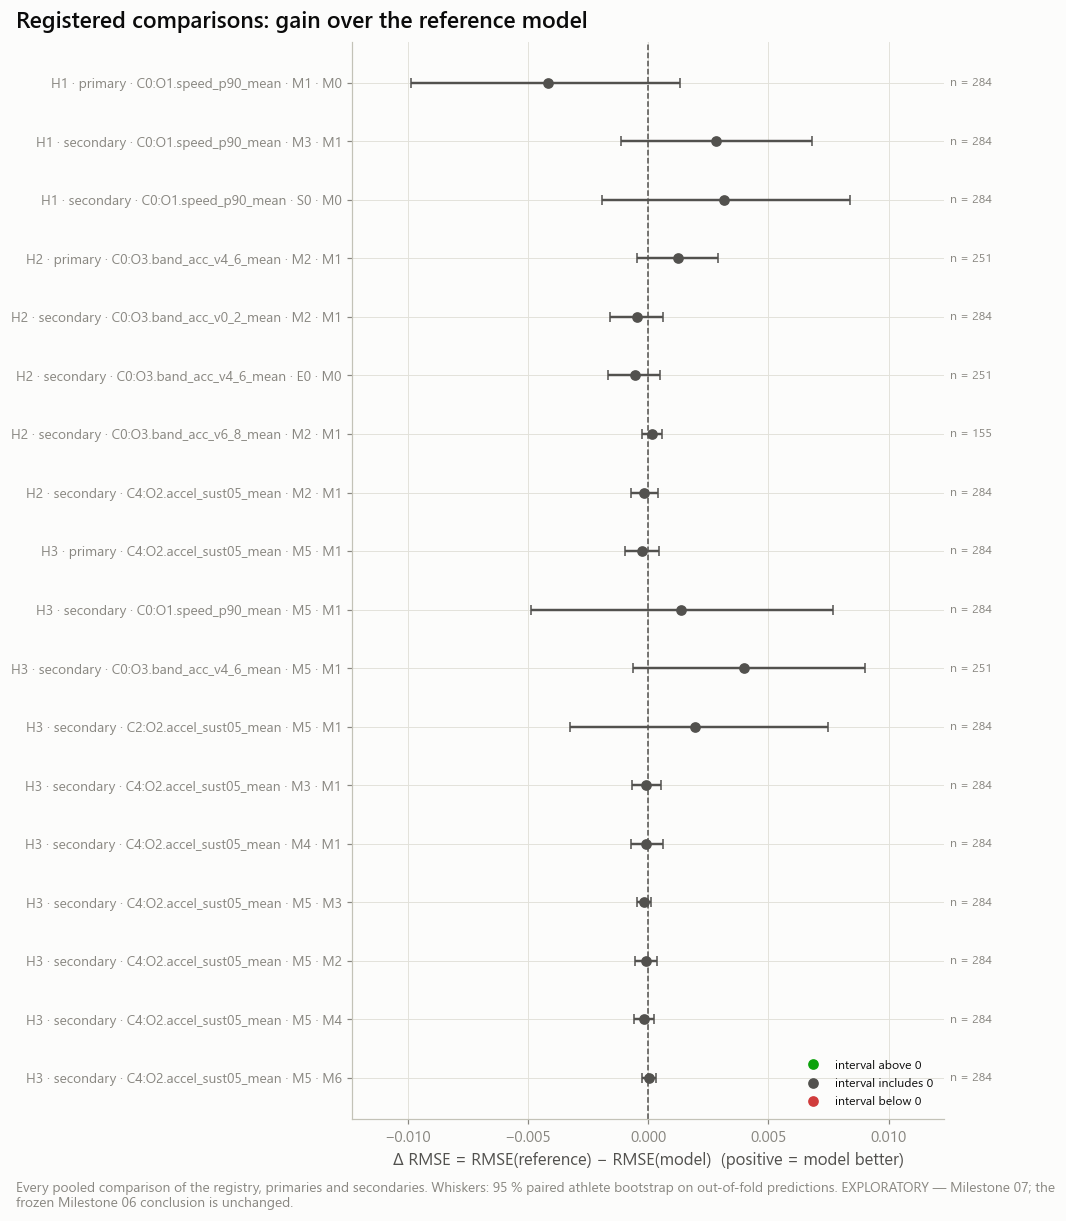

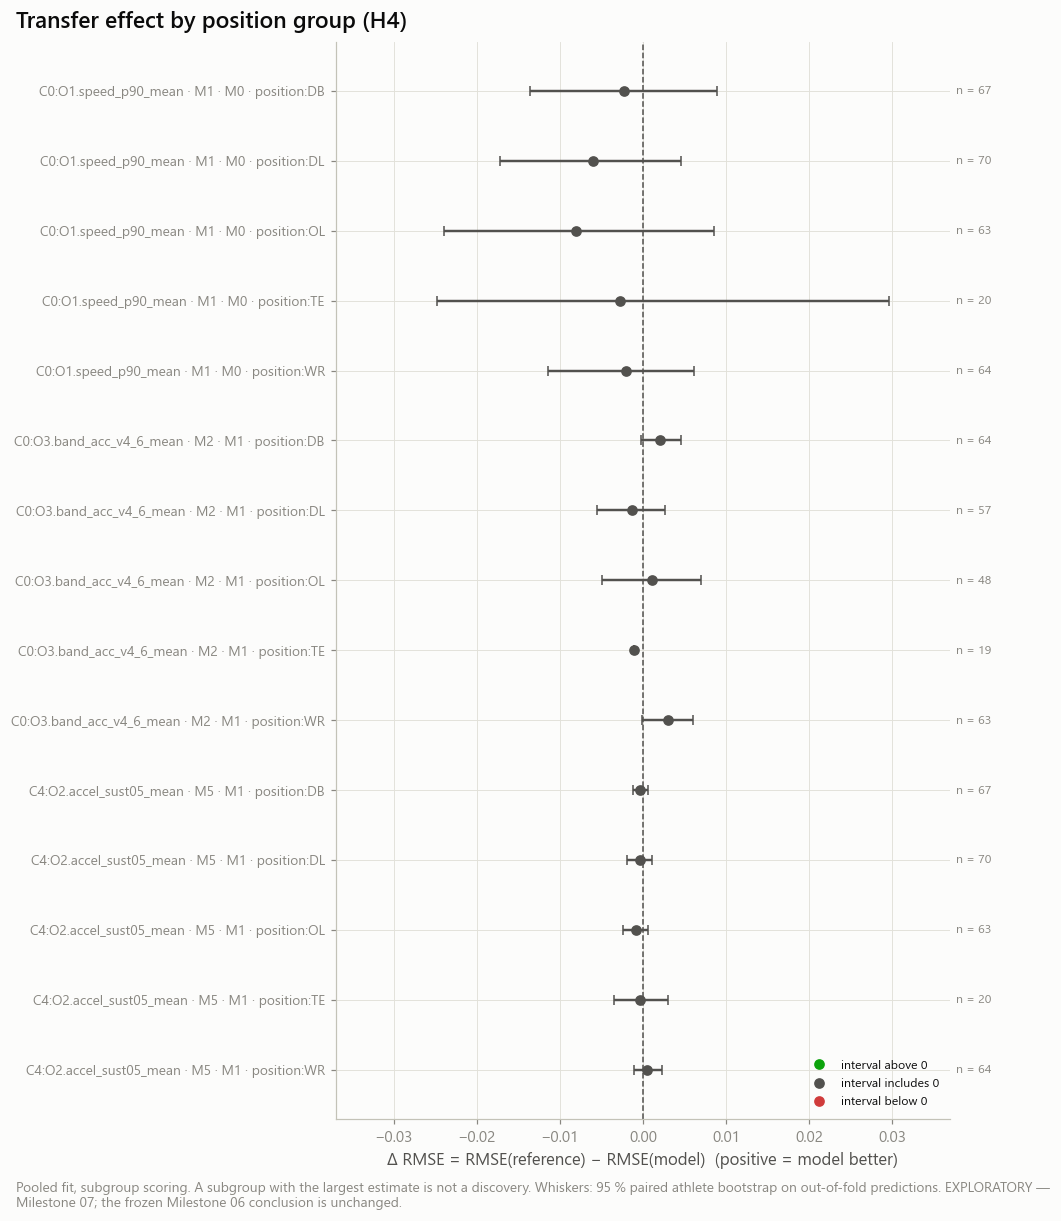

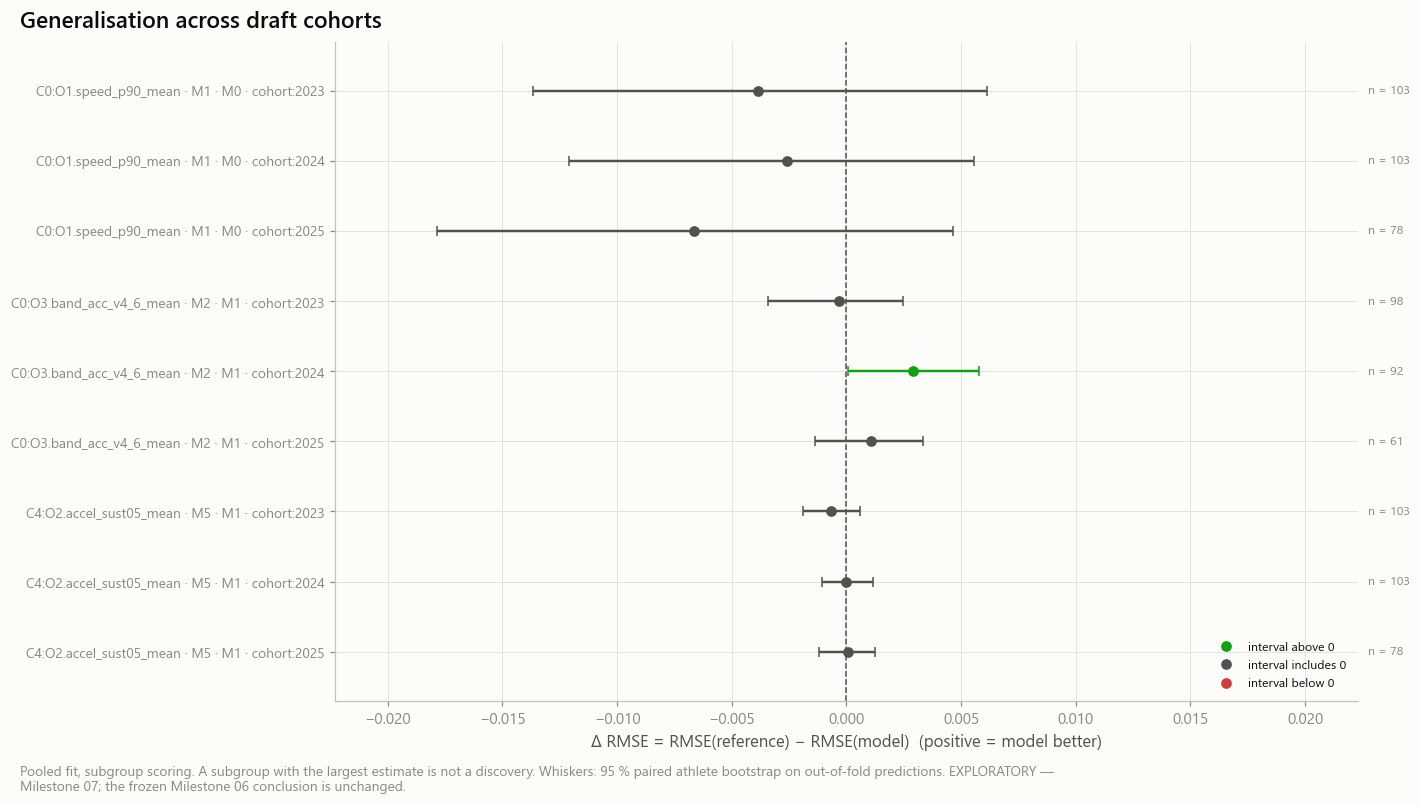

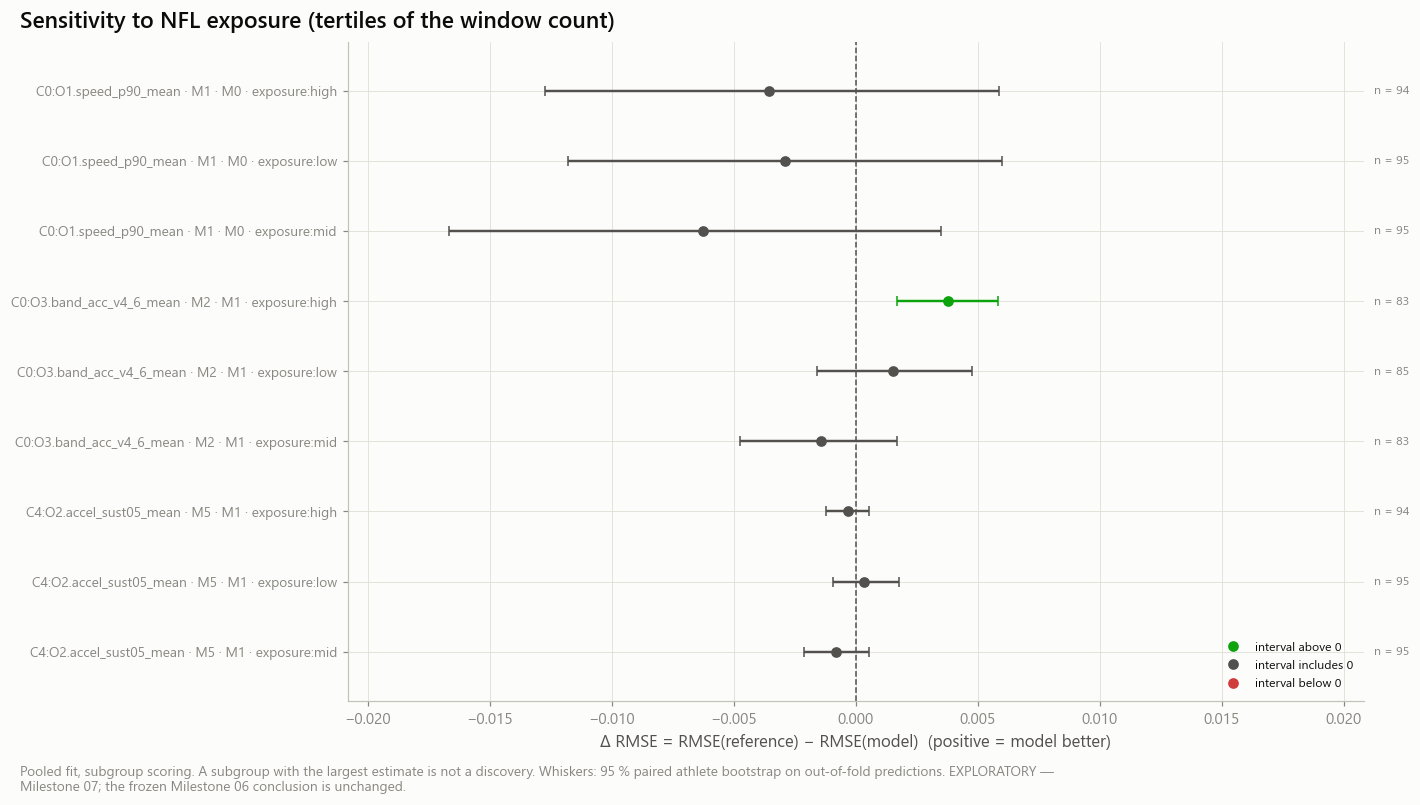

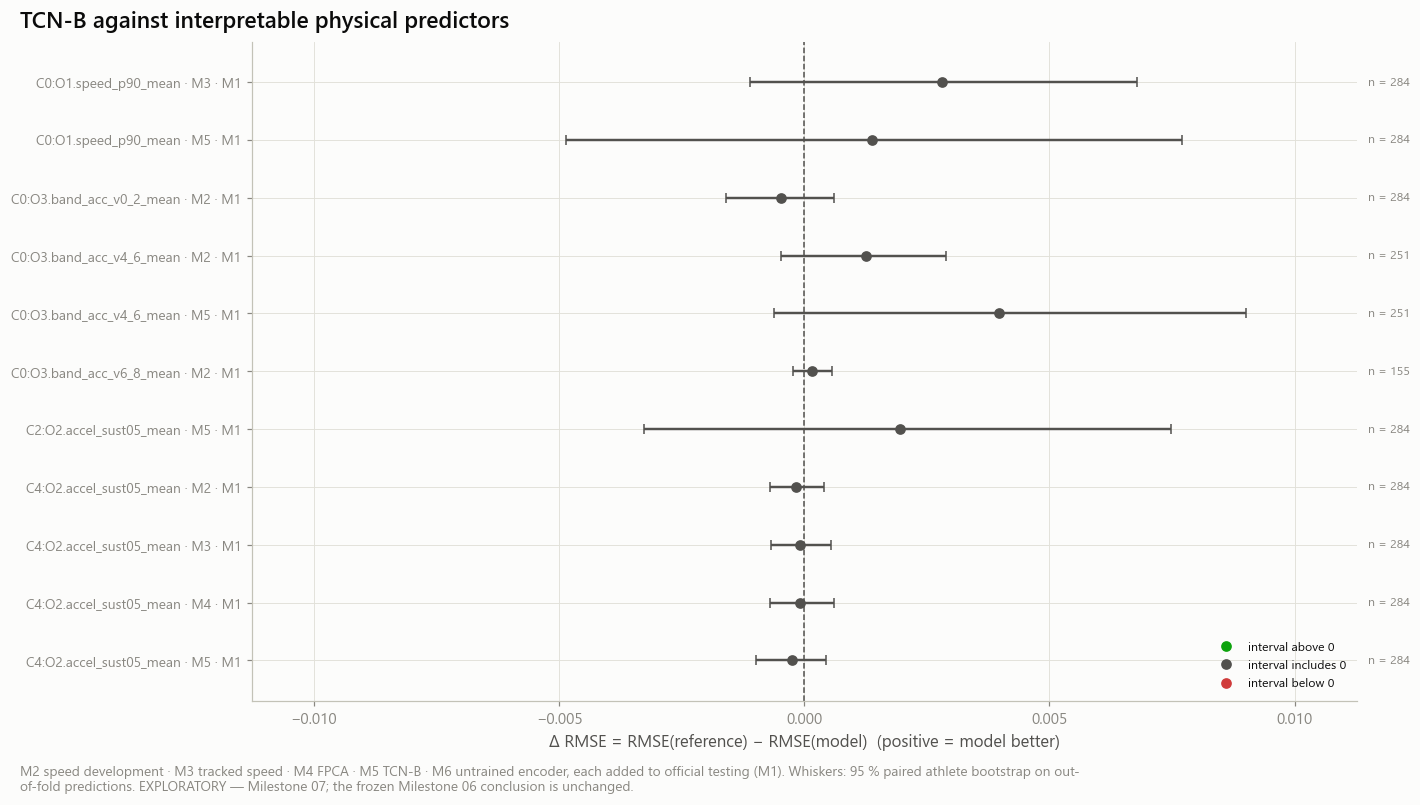

In [8]:
N_NOTE = f'paired Milestone 06 cohort ({design.n} athletes); each outcome on its eligible athletes'
store.show(cf.plot_paired_forest(pooled, 'Registered comparisons: gain over the reference model',
                                 'Every pooled comparison of the registry, primaries and secondaries.', ('hypothesis', 'tier', 'target_id', 'model', 'reference')),
           'AM07B_05_model_gains', {'paired': pooled}, publication=True, source='aligned_transfer_paired_uncertainty', n=N_NOTE)
for fig_no, kind, title in ((6, 'position', 'Transfer effect by position group (H4)'), (7, 'cohort', 'Generalisation across draft cohorts'),
                            (8, 'exposure', 'Sensitivity to NFL exposure (tertiles of the window count)')):
    sub = paired.filter(pl.col('analysis').str.starts_with(kind + ':') & (pl.col('metric') == 'delta_rmse')).sort('target_id', 'model', 'analysis')
    store.show(cf.plot_paired_forest(sub, title, 'Pooled fit, subgroup scoring. A subgroup with the largest estimate is not a discovery.',
                                     ('target_id', 'model', 'reference', 'analysis')),
               f'AM07B_{fig_no:02d}_gain_by_{kind}', {'paired': sub}, source='aligned_transfer_paired_uncertainty', n=N_NOTE)
vs_m1 = pooled.filter((pl.col('reference') == 'M1') & pl.col('model').is_in(['M2', 'M3', 'M4', 'M5', 'M6'])).sort('target_id', 'model')
store.show(cf.plot_paired_forest(vs_m1, 'TCN-B against interpretable physical predictors',
                                 'M2 speed development · M3 tracked speed · M4 FPCA · M5 TCN-B · M6 untrained encoder, each added to official testing (M1).'),
           'AM07B_10_tcn_vs_physical', {'paired': vs_m1}, publication=True, source='aligned_transfer_paired_uncertainty', n=N_NOTE)

## 5. Physical quantities side by side (descriptive, in-sample)

The out-of-fold comparisons above are the evidence. These plots and partial correlations show the raw physical relationships behind H1 and H2 — within position, and after removing the official forty, 10-yard split and weight. They are in-sample and are **not** transfer results.

hypothesis,feature,target_id,control,n_athletes,r,ci_lower,ci_upper,expected_sign,status
str,str,str,str,i64,f64,f64,f64,str,str
"""H1""","""tracked top speed p95 [yd/s]""","""C0:O1.speed_p90_mean""","""position""",284,0.455,0.371,0.535,"""+""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""
"""H1""","""tracked top speed p95 [yd/s]""","""C0:O1.speed_p90_mean""","""official""",284,0.147,0.036,0.261,"""+""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""
"""H1""","""official forty [s]""","""C0:O1.speed_p90_mean""","""position""",284,-0.452,-0.537,-0.356,"""−""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""
"""H1""","""official forty [s]""","""C0:O1.speed_p90_mean""","""official""",284,null,null,null,"""−""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""
"""H2""","""Combine accel 4→8 yd/s (4 / time) [yd/s²]""","""C0:O3.band_acc_v4_6_mean""","""position""",251,0.194,0.087,0.297,"""+""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""
"""H2""","""Combine accel 4→8 yd/s (4 / time) [yd/s²]""","""C0:O3.band_acc_v4_6_mean""","""official""",251,-0.078,-0.180,0.038,"""+""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""
"""H2""","""Combine accel 4→8 yd/s (4 / time) [yd/s²]""","""C0:O3.band_acc_v6_8_mean""","""position""",155,0.181,0.052,0.315,"""+""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""
"""H2""","""Combine accel 4→8 yd/s (4 / time) [yd/s²]""","""C0:O3.band_acc_v6_8_mean""","""official""",155,-0.051,-0.200,0.112,"""+""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""
"""H2""","""Combine accel 4→8 yd/s (4 / time) [yd/s²]""","""C0:O3.band_acc_v0_2_mean""","""position""",284,0.300,0.171,0.430,"""+""","""DESCRIPTIVE, in-sample · EXPLORATORY (Milestone 07B)"""


15:41:28 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B] aligned_transfer_physical_association: 12 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_physical_association.parquet


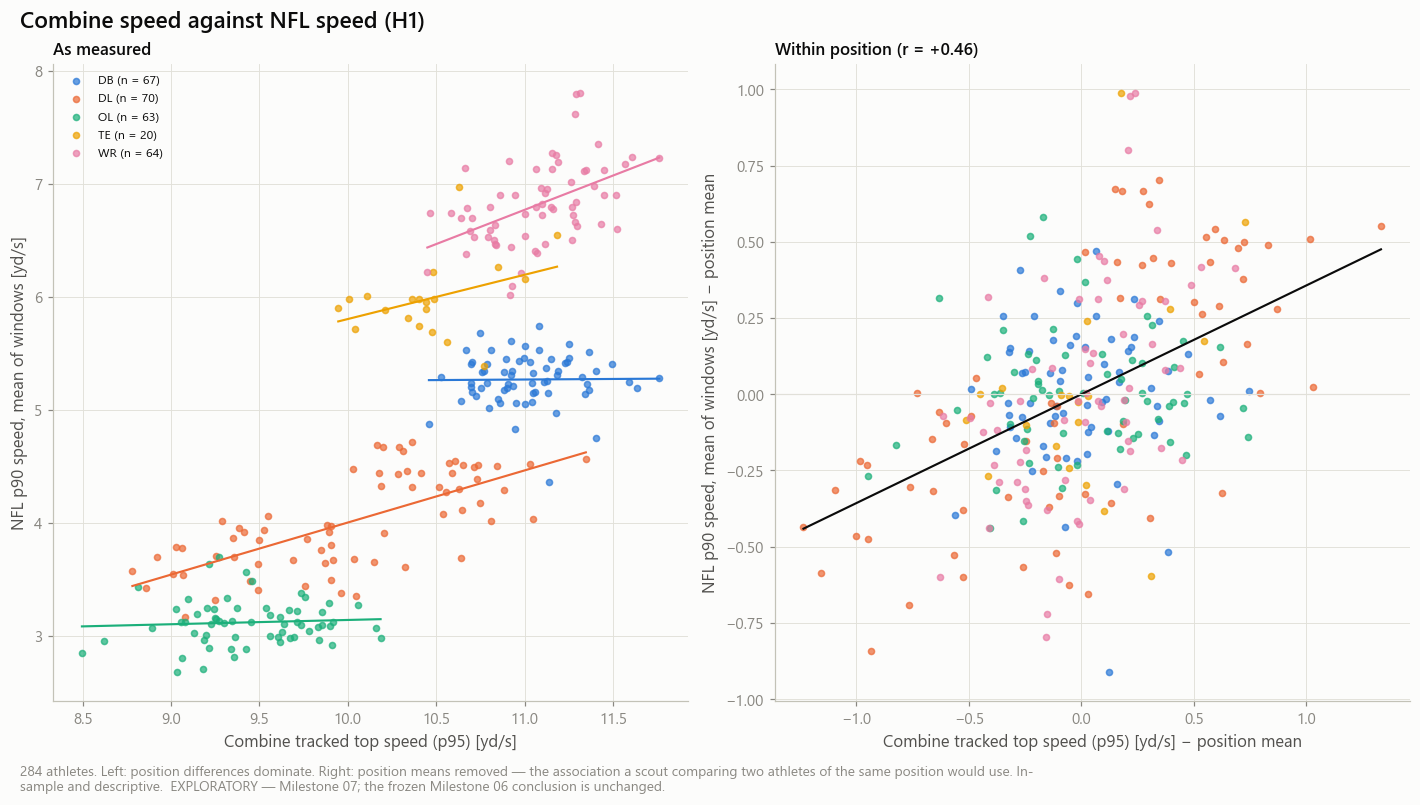

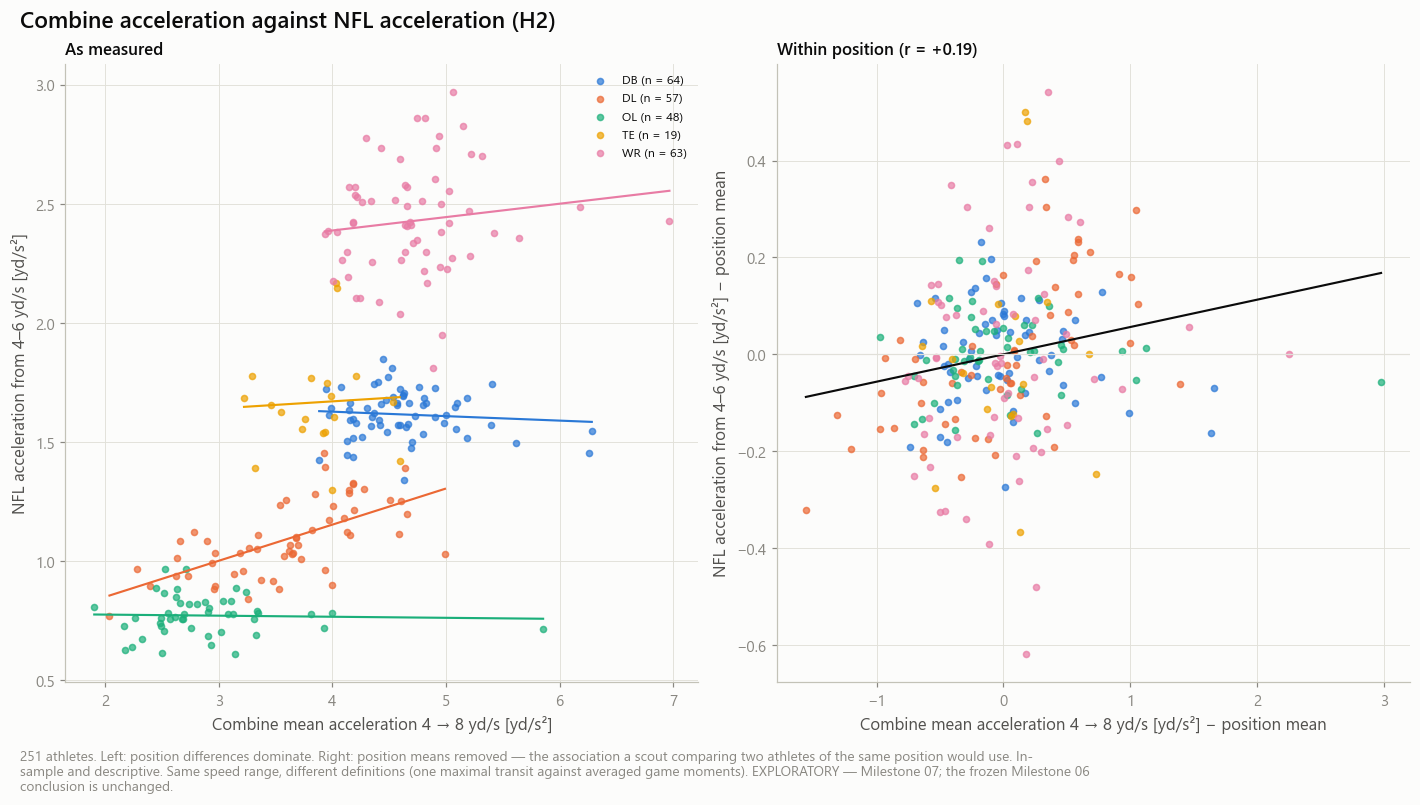

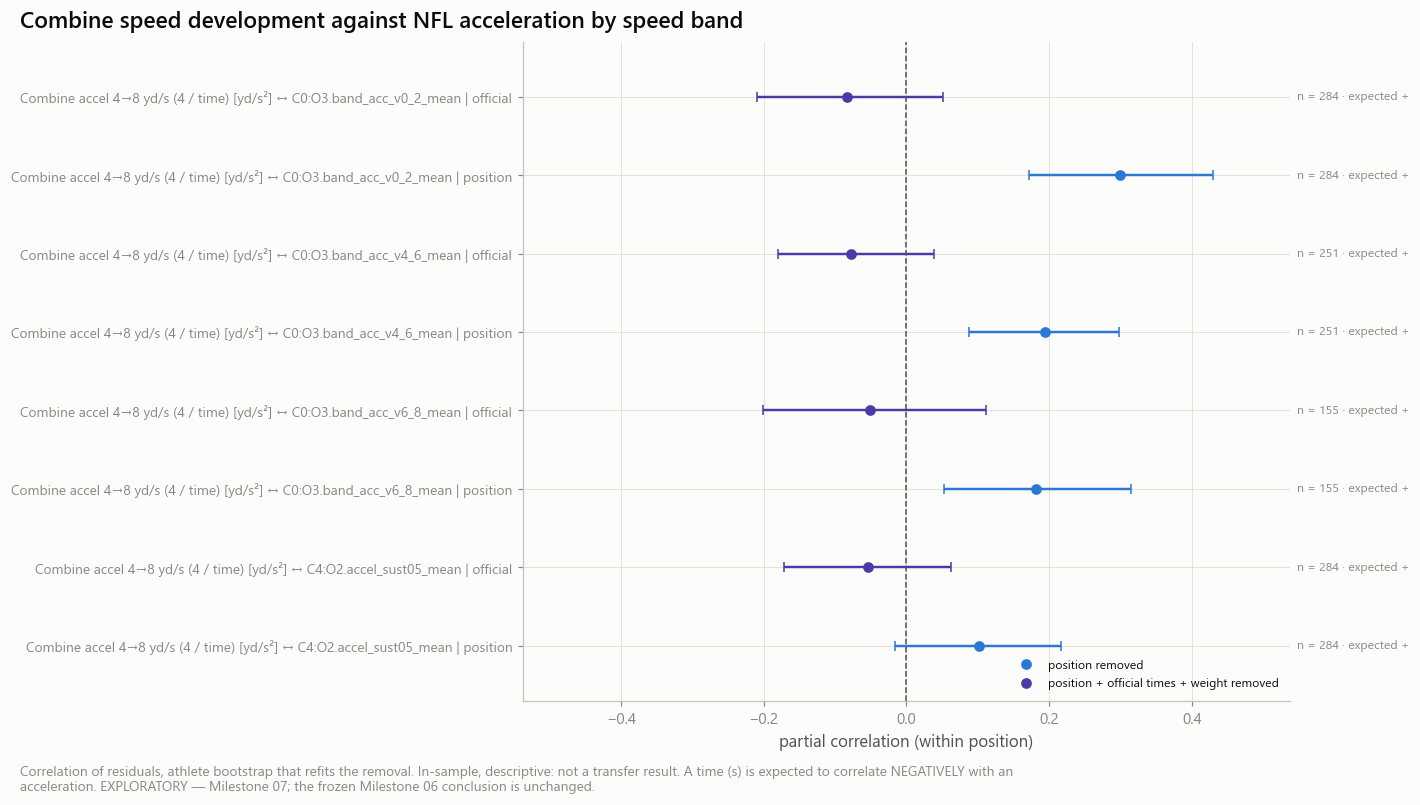

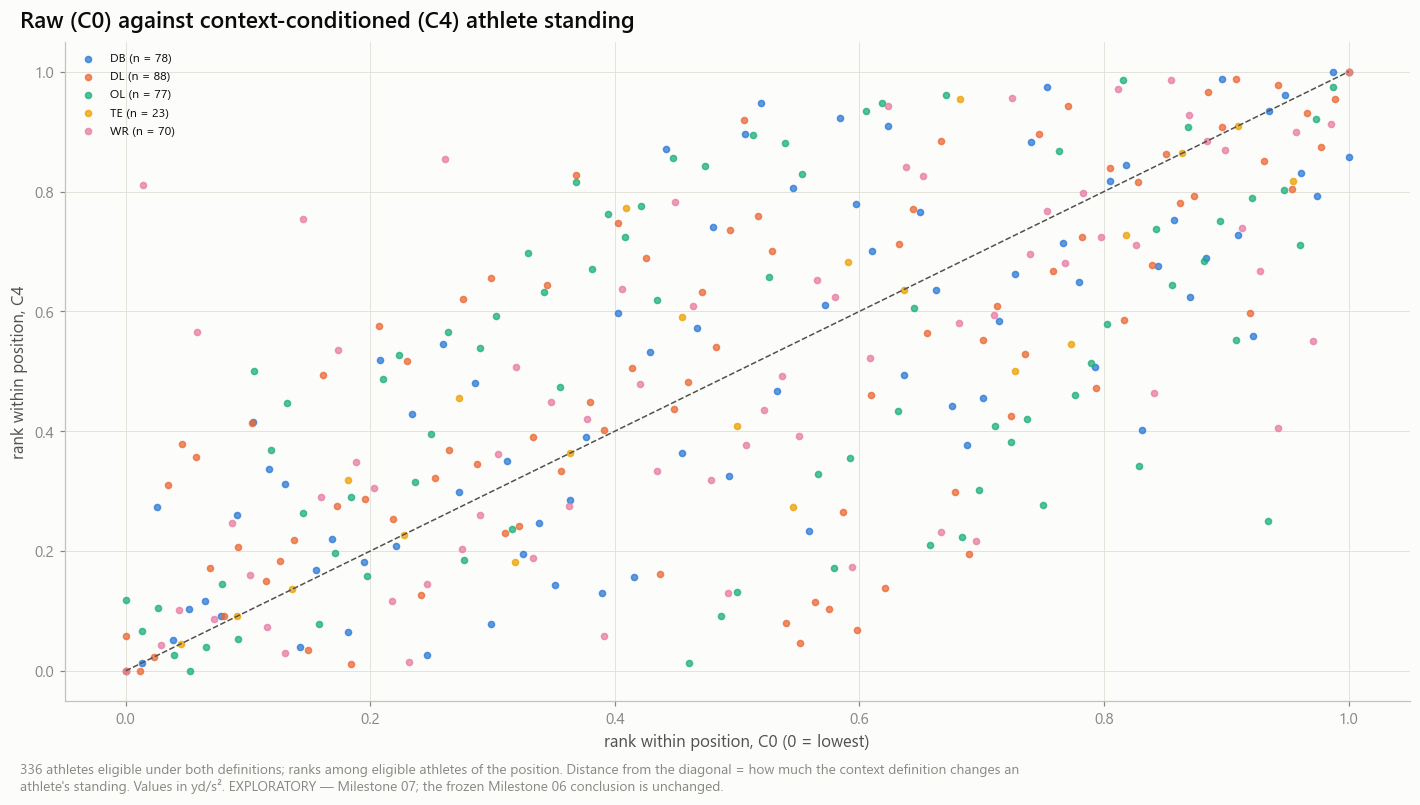

In [9]:
attempt_values = store.atlas.require(at.ATTEMPT_VALUES, NB['04A'])
af = pt.athlete_features(attempt_values, [pt.P95, pt.V4_V8])
fid = af['nfl_id'].to_numpy()
features = {'tracked top speed p95 [yd/s]': (fid, af[pt.P95].fill_null(np.nan).to_numpy()),
            'Combine accel 4→8 yd/s (4 / time) [yd/s²]': (fid, pt.v4_v8_mean_accel(af[pt.V4_V8].fill_null(np.nan).to_numpy())),
            'official forty [s]': (design.ids, design.numeric['cmb_forty'])}
desc = {}
for key in NEEDED:
    o = pt.OUTCOME[key]
    if labs[o.outcome_id].available(o.definition)[0]:
        v = labs[o.outcome_id].values(o.definition)                      # descriptive: context parameters from all athletes
        ok = v['n_windows'] >= cc.min_windows
        desc[o.target_id] = (v['ids'][ok], v['value'][ok])
T_ = lambda k: pt.OUTCOME[k].target_id
PLAN = [('H1', 'tracked top speed p95 [yd/s]', T_('Y_SPEED'), '+'), ('H1', 'official forty [s]', T_('Y_SPEED'), '−'),
        ('H2', 'Combine accel 4→8 yd/s (4 / time) [yd/s²]', T_('Y_BAND46'), '+'), ('H2', 'Combine accel 4→8 yd/s (4 / time) [yd/s²]', T_('Y_BAND68'), '+'),
        ('H2', 'Combine accel 4→8 yd/s (4 / time) [yd/s²]', T_('Y_BAND02'), '+'), ('H2', 'Combine accel 4→8 yd/s (4 / time) [yd/s²]', T_('Y_CTX'), '+')]
assoc = pt.association_table(features, desc, design, PLAN, ['cmb_forty', 'cmb_ten_yd_split', 'cmb_combine_weight'], min(tc.n_boot, 1000), controls.seed)
with pl.Config(tbl_rows=-1, float_precision=3, fmt_str_lengths=80):
    display(assoc)
if controls.save_tables:
    store.write(assoc, pt.ASSOC, '07B', {'plan': PLAN})

def on_design(pair):
    ids, v = pair
    pos = np.minimum(np.searchsorted(ids, design.ids), ids.size - 1)
    return np.where(ids[pos] == design.ids, np.asarray(v, dtype=float)[pos], np.nan)

if T_('Y_SPEED') in desc:
    store.show(cf.plot_feature_vs_outcome(on_design(features['tracked top speed p95 [yd/s]']), on_design(desc[T_('Y_SPEED')]), design.position,
                                          'Combine tracked top speed (p95) [yd/s]', 'NFL p90 speed, mean of windows [yd/s]', 'Combine speed against NFL speed (H1)'),
               'AM07B_01_combine_speed_vs_nfl_speed', {'association': assoc.filter(pl.col('hypothesis') == 'H1')}, publication=True, source='atlas_attempt_features + nfl_play_movement', n=N_NOTE)
if T_('Y_BAND46') in desc:
    store.show(cf.plot_feature_vs_outcome(on_design(features['Combine accel 4→8 yd/s (4 / time) [yd/s²]']), on_design(desc[T_('Y_BAND46')]), design.position,
                                          'Combine mean acceleration 4 → 8 yd/s [yd/s²]', 'NFL acceleration from 4–6 yd/s [yd/s²]', 'Combine acceleration against NFL acceleration (H2)',
                                          'Same speed range, different definitions (one maximal transit against averaged game moments).'),
               'AM07B_02_combine_accel_vs_nfl_accel', {'association': assoc.filter(pl.col('hypothesis') == 'H2')}, publication=True, source='atlas_attempt_features + nfl_play_movement', n=N_NOTE)
store.show(cf.plot_associations(assoc.filter(pl.col('hypothesis') == 'H2'), 'Combine speed development against NFL acceleration by speed band'),
           'AM07B_03_speed_band_alignment', {'association': assoc}, source='aligned_transfer_physical_association', n=N_NOTE)
adjusted = store.require(co.ADJUSTED, NB['07A'])
store.show(cf.plot_raw_vs_adjusted(adjusted, 'C4' if 'C4' in m07a['definitions_available'] else m07a['definitions_available'][-1], m07a['unit']),
           'AM07B_04_context_adjusted_vs_raw', {'adjusted': adjusted}, source='nfl_context_adjusted_outcomes (07A)', n=f'{m07a["n_athletes"]} NFL athletes')

## 6. Matched prospects

The matched pairs frozen in 06C: same position, near-identical official forty, 10-yard split and body size — a rule that uses pre-NFL information only. No pair is chosen because its outcome is interesting; a pair is kept for an outcome when both athletes have an out-of-fold prediction. Distinct athletes and pair reuse are reported; the bootstrap resamples athletes, not pairs.

15:41:34 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:07B_matched] computing (never run)
15:41:35 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B_matched] aligned_transfer_matched_pairs: 77 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_matched_pairs.parquet


target_id,model,n_pairs,n_athletes,max_pairs_per_athlete,concordance,ci_lower,ci_upper,delta_vs_reference,delta_ci_lower,delta_ci_upper,diff_correlation,status
str,str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,str
"""C0:O3.band_acc_v0_2_mean""","""M0""",833,275,14,0.510,0.447,0.574,0.014,-0.037,0.064,0.029,"""EXPLORATORY (Milestone 07B)"""
"""C0:O3.band_acc_v0_2_mean""","""M1""",833,275,14,0.496,0.430,0.561,null,null,null,-0.023,"""EXPLORATORY (Milestone 07B)"""
"""C0:O3.band_acc_v0_2_mean""","""M2""",833,275,14,0.492,0.427,0.555,-0.004,-0.033,0.023,-0.029,"""EXPLORATORY (Milestone 07B)"""
"""C0:O3.band_acc_v0_2_mean""","""M3""",833,275,14,0.508,0.439,0.574,0.012,-0.019,0.043,-0.028,"""EXPLORATORY (Milestone 07B)"""
"""C0:O3.band_acc_v0_2_mean""","""M4""",833,275,14,0.507,0.436,0.575,0.011,-0.032,0.052,-0.025,"""EXPLORATORY (Milestone 07B)"""
"""C0:O3.band_acc_v0_2_mean""","""M5""",833,275,14,0.462,0.397,0.530,-0.034,-0.084,0.017,-0.107,"""EXPLORATORY (Milestone 07B)"""
"""C0:O3.band_acc_v0_2_mean""","""M6""",833,275,14,0.489,0.422,0.552,-0.007,-0.060,0.049,-0.053,"""EXPLORATORY (Milestone 07B)"""
"""C0:O3.band_acc_v0_2_mean""","""S0""",833,275,14,0.504,0.439,0.567,0.008,-0.034,0.052,0.001,"""EXPLORATORY (Milestone 07B)"""
"""C0:O3.band_acc_v0_2_mean""","""E0""",833,275,14,0.544,0.480,0.605,0.048,0.007,0.091,0.033,"""EXPLORATORY (Milestone 07B)"""


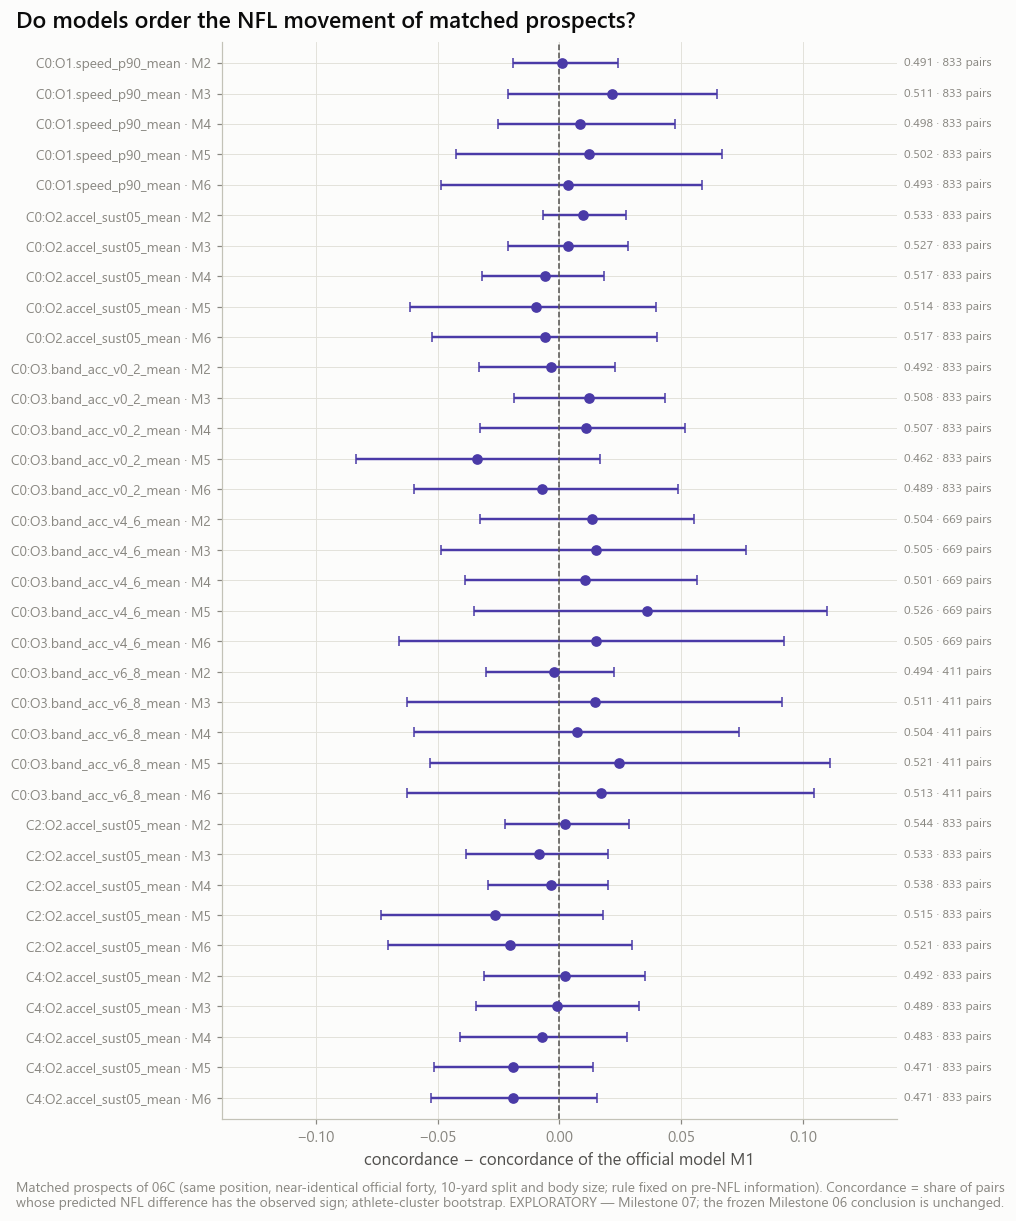

In [10]:
m06_pairs = T.require(tx.PAIRS, NB['06C'])
stage6 = store.build('07B_matched', [pt.MATCHED], lambda: {pt.MATCHED.name: pt.pair_concordance(m06_pairs, oof, tc, controls.seed)}, PARAMS,
                     [store.parquet(pt.ALIGNED_OOF), T.parquet(tx.PAIRS)])
matched = stage6[pt.MATCHED.name]
with pl.Config(tbl_rows=-1, float_precision=3):
    display(matched.filter(pl.col('model').is_in(['M0', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'S0', 'E0'])))
store.show(cf.plot_matched(matched.filter(pl.col('model').is_in(['M2', 'M3', 'M4', 'M5', 'M6']))), 'AM07B_09_matched_prospects', {'matched': matched},
           source='aligned_transfer_matched_pairs', n=f'{m06_pairs.height} frozen pairs')

## 7. Milestone 06 beside Milestone 07, gate 07B, interpretation

The confirmatory Milestone 06 rows are read from disk unchanged and shown beside the exploratory rows of this notebook, on the common scale "% of the reference error". Gate 07B does **not** require a positive gain: it certifies that the hypotheses were fixed first, comparable quantities were used, predictions were athlete-held-out, baselines were included, paired uncertainty was computed and the exploratory status is explicit.

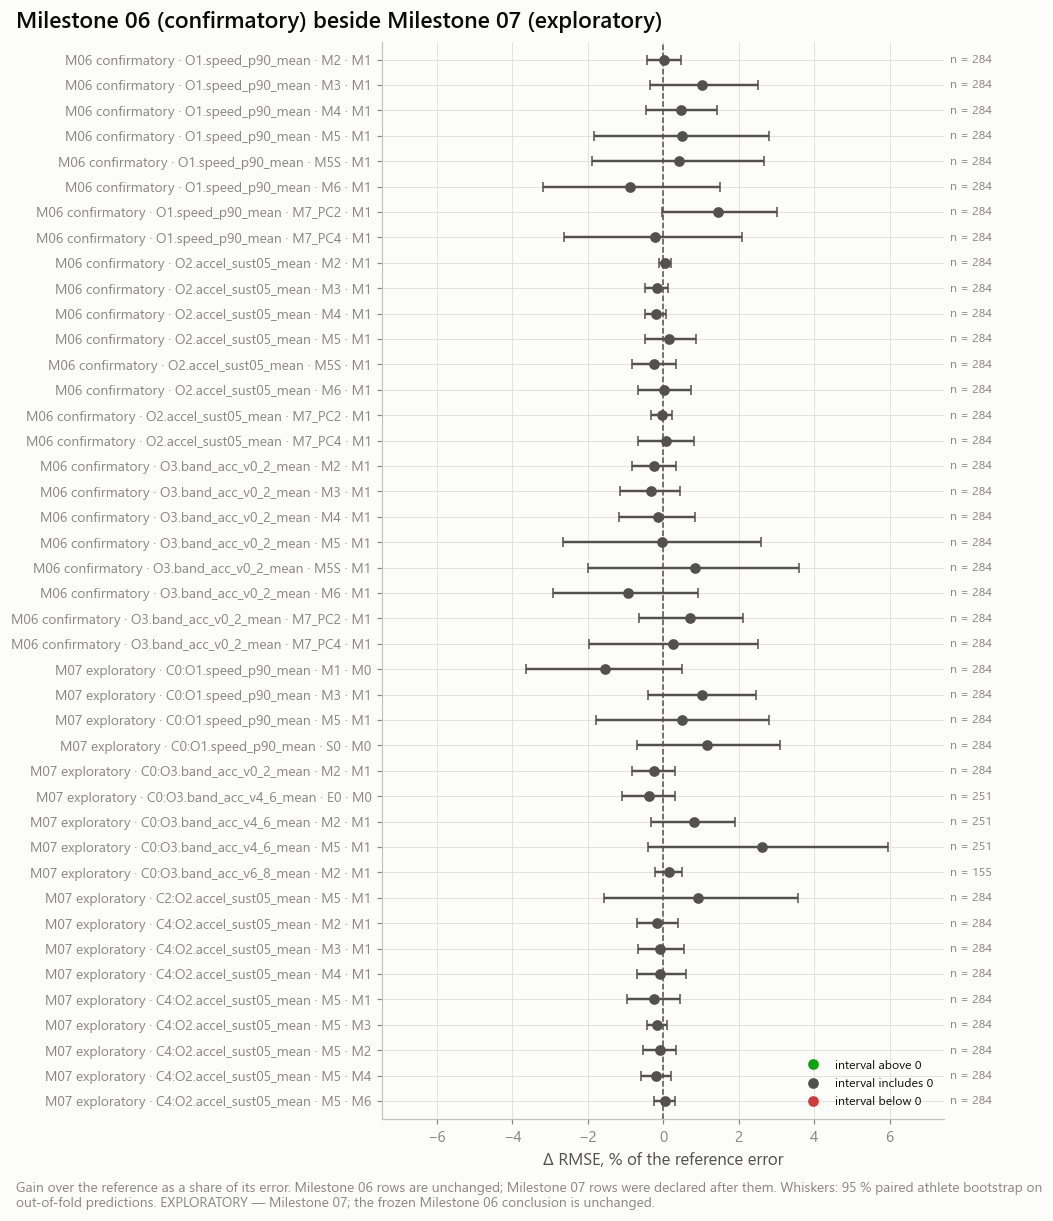

criterion,passed,detail
str,bool,str
"""hypotheses_fixed_before_evaluation""",true,"""21 registered comparison(s); the registry was persisted before the first model was fitted"""
"""comparable_physical_quantities""",true,"""unit checks pass; definitional mismatches are stated in the audit"""
"""athlete_held_out_predictions""",true,"""7 outcome(s); identical athletes for every model of an outcome: True; one prediction per athlete and model: True"""
"""baselines_included""",true,"""M0 and M1 evaluated on every outcome"""
"""paired_uncertainty_calculated""",true,"""18 registered pooled comparison(s) with an interval"""
"""exploratory_status_explicit""",true,"""EXPLORATORY (Milestone 07B)"""
"""coverage_reported (informative)""",true,"""outcomes not evaluated: none"""


# Physically aligned transfer — interpretation (Milestone 07B)

**Status: EXPLORATORY (Milestone 07B).** Milestone 06 remains the confirmatory study (no method shown to improve on official Combine testing). Nothing below is a confirmatory finding; an interval that excludes 0 here is a hypothesis for an independent cohort.

## H1 — Combine speed → NFL speed (positive control)

| Tier | Outcome | Model vs reference | n | Δ RMSE [95 %] | Relative | Holm p (primaries) | Reading |
|---|---|---|---|---|---|---|---|
| primary | `C0:O1.speed_p90_mean` | M1 vs M0 | 284 | -0.0041 [-0.0098, +0.0013] | -1.5 % | 0.453 | not established (interval includes 0) |
| secondary | `C0:O1.speed_p90_mean` | M3 vs M1 | 284 | +0.0028 [-0.0011, +0.0068] | +1.0 % | n/a | not established (interval includes 0) |
| secondary | `C0:O1.speed_p90_mean` | S0 vs M0 | 284 | +0.0032 [-0.0019, +0.0084] | +1.2 % | n/a | not established (interval includes 0) |

## H2 — Combine speed development → NFL acceleration

| Tier | Outcome | Model vs reference | n | Δ RMSE [95 %] | Relative | Holm p (primaries) | Reading |
|---|---|---|---|---|---|---|---|
| primary | `C0:O3.band_acc_v4_6_mean` | M2 vs M1 | 251 | +0.0013 [-0.0005, +0.0029] | +0.8 % | 0.453 | not established (interval includes 0) |
| secondary | `C0:O3.band_acc_v0_2_mean` | M2 vs M1 | 284 | -0.0005 [-0.0016, +0.0006] | -0.2 % | n/a | not established (interval includes 0) |
| secondary | `C0:O3.band_acc_v4_6_mean` | E0 vs M0 | 251 | -0.0005 [-0.0016, +0.0005] | -0.4 % | n/a | not established (interval includes 0) |
| secondary | `C0:O3.band_acc_v6_8_mean` | M2 vs M1 | 155 | +0.0002 [-0.0002, +0.0006] | +0.1 % | n/a | not established (interval includes 0) |
| secondary | `C4:O2.accel_sust05_mean` | M2 vs M1 | 284 | -0.0002 [-0.0007, +0.0004] | -0.2 % | n/a | not established (interval includes 0) |

## H3 — TCN-B beyond official measurements

| Tier | Outcome | Model vs reference | n | Δ RMSE [95 %] | Relative | Holm p (primaries) | Reading |
|---|---|---|---|---|---|---|---|
| primary | `C4:O2.accel_sust05_mean` | M5 vs M1 | 284 | -0.0003 [-0.0010, +0.0004] | -0.3 % | 0.521 | not established (interval includes 0) |
| secondary | `C0:O1.speed_p90_mean` | M5 vs M1 | 284 | +0.0014 [-0.0049, +0.0077] | +0.5 % | n/a | not established (interval includes 0) |
| secondary | `C0:O3.band_acc_v4_6_mean` | M5 vs M1 | 251 | +0.0040 [-0.0006, +0.0090] | +2.6 % | n/a | not established (interval includes 0) |
| secondary | `C2:O2.accel_sust05_mean` | M5 vs M1 | 284 | +0.0019 [-0.0033, +0.0075] | +0.9 % | n/a | not established (interval includes 0) |
| secondary | `C4:O2.accel_sust05_mean` | M3 vs M1 | 284 | -0.0001 [-0.0007, +0.0006] | -0.1 % | n/a | not established (interval includes 0) |
| secondary | `C4:O2.accel_sust05_mean` | M4 vs M1 | 284 | -0.0001 [-0.0007, +0.0006] | -0.1 % | n/a | not established (interval includes 0) |
| secondary | `C4:O2.accel_sust05_mean` | M5 vs M3 | 284 | -0.0002 [-0.0004, +0.0001] | -0.2 % | n/a | not established (interval includes 0) |
| secondary | `C4:O2.accel_sust05_mean` | M5 vs M2 | 284 | -0.0001 [-0.0006, +0.0004] | -0.1 % | n/a | not established (interval includes 0) |
| secondary | `C4:O2.accel_sust05_mean` | M5 vs M4 | 284 | -0.0002 [-0.0006, +0.0002] | -0.2 % | n/a | not established (interval includes 0) |
| secondary | `C4:O2.accel_sust05_mean` | M5 vs M6 | 284 | +0.0000 [-0.0002, +0.0003] | +0.0 % | n/a | not established (interval includes 0) |

## H4 — position-conditioned transfer

- `C0:O1.speed_p90_mean` M1 vs M0, position:DB (n = 67): -0.0022 [-0.0135, +0.0090]
- `C0:O1.speed_p90_mean` M1 vs M0, position:DL (n = 70): -0.0060 [-0.0173, +0.0046]
- `C0:O1.speed_p90_mean` M1 vs M0, position:OL (n = 63): -0.0080 [-0.0239, +0.0086]
- `C0:O1.speed_p90_mean` M1 vs M0, position:TE (n = 20): -0.0028 [-0.0247, +0.0296]
- `C0:O1.speed_p90_mean` M1 vs M0, position:WR (n = 64): -0.0020 [-0.0114, +0.0061]
- `C0:O3.band_acc_v4_6_mean` M2 vs M1, position:DB (n = 64): +0.0021 [-0.0003, +0.0045]
- `C0:O3.band_acc_v4_6_mean` M2 vs M1, position:DL (n = 57): -0.0013 [-0.0056, +0.0027]
- `C0:O3.band_acc_v4_6_mean` M2 vs M1, position:OL (n = 48): +0.0011 [-0.0050, +0.0069]
- `C0:O3.band_acc_v4_6_mean` M2 vs M1, position:TE (n = 19): -0.0011 [n/a, n/a]
- `C0:O3.band_acc_v4_6_mean` M2 vs M1, position:WR (n = 63): +0.0030 [-0.0001, +0.0060]
- `C4:O2.accel_sust05_mean` M5 vs M1, position:DB (n = 67): -0.0003 [-0.0012, +0.0006]
- `C4:O2.accel_sust05_mean` M5 vs M1, position:DL (n = 70): -0.0004 [-0.0019, +0.0011]
- `C4:O2.accel_sust05_mean` M5 vs M1, position:OL (n = 63): -0.0009 [-0.0024, +0.0006]
- `C4:O2.accel_sust05_mean` M5 vs M1, position:TE (n = 20): -0.0004 [-0.0034, +0.0031]
- `C4:O2.accel_sust05_mean` M5 vs M1, position:WR (n = 64): +0.0005 [-0.0010, +0.0023]

Subgroups are scored from the pooled fit and are exploratory: the group with the largest estimate is not a discovery.

## Matched prospects

- `C0:O1.speed_p90_mean` E0: concordance 0.513 [+0.446, +0.576], vs official +0.023 [-0.024, +0.068] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` M0: concordance 0.522 [+0.455, +0.587], vs official +0.032 [-0.012, +0.078] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` M1: concordance 0.490 [+0.425, +0.554], vs official n/a [n/a, n/a] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` M2: concordance 0.491 [+0.427, +0.556], vs official +0.001 [-0.019, +0.024] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` M3: concordance 0.511 [+0.449, +0.572], vs official +0.022 [-0.021, +0.064] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` M4: concordance 0.498 [+0.435, +0.558], vs official +0.008 [-0.025, +0.047] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` M5: concordance 0.502 [+0.438, +0.564], vs official +0.012 [-0.043, +0.067] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` M6: concordance 0.493 [+0.425, +0.559], vs official +0.004 [-0.048, +0.058] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` MEAN: concordance 0.454 [+0.387, +0.515], vs official -0.036 [-0.126, +0.051] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` POS: concordance 0.444 [+0.380, +0.506], vs official -0.046 [-0.122, +0.032] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O1.speed_p90_mean` S0: concordance 0.519 [+0.454, +0.584], vs official +0.029 [-0.017, +0.077] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` E0: concordance 0.546 [+0.478, +0.617], vs official +0.023 [-0.027, +0.075] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` M0: concordance 0.535 [+0.468, +0.604], vs official +0.012 [-0.040, +0.068] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` M1: concordance 0.523 [+0.454, +0.592], vs official n/a [n/a, n/a] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` M2: concordance 0.533 [+0.462, +0.603], vs official +0.010 [-0.007, +0.027] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` M3: concordance 0.527 [+0.458, +0.596], vs official +0.004 [-0.021, +0.028] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` M4: concordance 0.517 [+0.450, +0.584], vs official -0.006 [-0.032, +0.018] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` M5: concordance 0.514 [+0.441, +0.579], vs official -0.010 [-0.061, +0.040] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` M6: concordance 0.517 [+0.449, +0.584], vs official -0.006 [-0.052, +0.040] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` MEAN: concordance 0.490 [+0.423, +0.550], vs official -0.034 [-0.127, +0.061] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` POS: concordance 0.435 [+0.372, +0.501], vs official -0.089 [-0.180, +0.003] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O2.accel_sust05_mean` S0: concordance 0.535 [+0.468, +0.601], vs official +0.012 [-0.032, +0.061] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` E0: concordance 0.544 [+0.480, +0.605], vs official +0.048 [+0.007, +0.091] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` M0: concordance 0.510 [+0.447, +0.574], vs official +0.014 [-0.037, +0.064] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` M1: concordance 0.496 [+0.430, +0.561], vs official n/a [n/a, n/a] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` M2: concordance 0.492 [+0.427, +0.555], vs official -0.004 [-0.033, +0.023] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` M3: concordance 0.508 [+0.439, +0.574], vs official +0.012 [-0.019, +0.043] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` M4: concordance 0.507 [+0.436, +0.575], vs official +0.011 [-0.032, +0.052] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` M5: concordance 0.462 [+0.397, +0.530], vs official -0.034 [-0.084, +0.017] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` M6: concordance 0.489 [+0.422, +0.552], vs official -0.007 [-0.060, +0.049] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` MEAN: concordance 0.485 [+0.423, +0.546], vs official -0.011 [-0.098, +0.074] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` POS: concordance 0.447 [+0.386, +0.510], vs official -0.049 [-0.133, +0.038] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v0_2_mean` S0: concordance 0.504 [+0.439, +0.567], vs official +0.008 [-0.034, +0.052] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` E0: concordance 0.516 [+0.443, +0.595], vs official +0.025 [-0.039, +0.090] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` M0: concordance 0.511 [+0.437, +0.593], vs official +0.021 [-0.042, +0.089] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` M1: concordance 0.490 [+0.421, +0.569], vs official n/a [n/a, n/a] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` M2: concordance 0.504 [+0.429, +0.581], vs official +0.013 [-0.033, +0.055] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` M3: concordance 0.505 [+0.437, +0.580], vs official +0.015 [-0.048, +0.076] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` M4: concordance 0.501 [+0.432, +0.575], vs official +0.010 [-0.039, +0.056] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` M5: concordance 0.526 [+0.455, +0.600], vs official +0.036 [-0.035, +0.110] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` M6: concordance 0.505 [+0.436, +0.576], vs official +0.015 [-0.066, +0.092] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` MEAN: concordance 0.466 [+0.397, +0.537], vs official -0.024 [-0.110, +0.065] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` POS: concordance 0.423 [+0.356, +0.491], vs official -0.067 [-0.168, +0.029] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v4_6_mean` S0: concordance 0.487 [+0.409, +0.563], vs official -0.003 [-0.083, +0.074] (669 pairs, 241 athletes, an athlete in up to 14 pairs)
- `C0:O3.band_acc_v6_8_mean` E0: concordance 0.472 [+0.381, +0.566], vs official -0.024 [-0.132, +0.090] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` M0: concordance 0.491 [+0.408, +0.585], vs official -0.005 [-0.110, +0.104] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` M1: concordance 0.496 [+0.401, +0.597], vs official n/a [n/a, n/a] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` M2: concordance 0.494 [+0.402, +0.596], vs official -0.002 [-0.030, +0.023] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` M3: concordance 0.511 [+0.416, +0.605], vs official +0.015 [-0.063, +0.091] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` M4: concordance 0.504 [+0.402, +0.602], vs official +0.007 [-0.059, +0.074] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` M5: concordance 0.521 [+0.424, +0.619], vs official +0.024 [-0.053, +0.111] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` M6: concordance 0.513 [+0.410, +0.613], vs official +0.017 [-0.063, +0.104] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` MEAN: concordance 0.510 [+0.418, +0.604], vs official +0.013 [-0.130, +0.162] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` POS: concordance 0.425 [+0.338, +0.519], vs official -0.072 [-0.195, +0.051] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C0:O3.band_acc_v6_8_mean` S0: concordance 0.557 [+0.455, +0.651], vs official +0.061 [-0.040, +0.160] (411 pairs, 147 athletes, an athlete in up to 13 pairs)
- `C2:O2.accel_sust05_mean` E0: concordance 0.549 [+0.477, +0.617], vs official +0.007 [-0.044, +0.059] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` M0: concordance 0.527 [+0.460, +0.597], vs official -0.014 [-0.073, +0.038] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` M1: concordance 0.541 [+0.475, +0.609], vs official n/a [n/a, n/a] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` M2: concordance 0.544 [+0.475, +0.614], vs official +0.002 [-0.022, +0.029] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` M3: concordance 0.533 [+0.464, +0.600], vs official -0.008 [-0.038, +0.020] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` M4: concordance 0.538 [+0.468, +0.608], vs official -0.004 [-0.029, +0.020] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` M5: concordance 0.515 [+0.446, +0.585], vs official -0.026 [-0.073, +0.018] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` M6: concordance 0.521 [+0.454, +0.586], vs official -0.020 [-0.070, +0.030] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` MEAN: concordance 0.496 [+0.432, +0.558], vs official -0.046 [-0.134, +0.043] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` POS: concordance 0.448 [+0.385, +0.511], vs official -0.094 [-0.188, -0.003] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C2:O2.accel_sust05_mean` S0: concordance 0.537 [+0.474, +0.603], vs official -0.005 [-0.056, +0.042] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` E0: concordance 0.430 [+0.359, +0.504], vs official -0.060 [-0.125, +0.008] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` M0: concordance 0.461 [+0.387, +0.535], vs official -0.029 [-0.104, +0.044] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` M1: concordance 0.490 [+0.421, +0.561], vs official n/a [n/a, n/a] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` M2: concordance 0.492 [+0.421, +0.566], vs official +0.002 [-0.031, +0.035] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` M3: concordance 0.489 [+0.418, +0.561], vs official -0.001 [-0.034, +0.033] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` M4: concordance 0.483 [+0.412, +0.553], vs official -0.007 [-0.041, +0.028] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` M5: concordance 0.471 [+0.403, +0.543], vs official -0.019 [-0.051, +0.014] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` M6: concordance 0.471 [+0.402, +0.541], vs official -0.019 [-0.053, +0.015] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` MEAN: concordance 0.474 [+0.412, +0.536], vs official -0.016 [-0.101, +0.070] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` POS: concordance 0.456 [+0.395, +0.523], vs official -0.034 [-0.091, +0.023] (833 pairs, 275 athletes, an athlete in up to 14 pairs)
- `C4:O2.accel_sust05_mean` S0: concordance 0.432 [+0.362, +0.507], vs official -0.058 [-0.124, +0.015] (833 pairs, 275 athletes, an athlete in up to 14 pairs)

## Descriptive physical associations (in-sample)

- tracked top speed p95 [yd/s] ↔ `C0:O1.speed_p90_mean` after position (n = 284): r = +0.455 [+0.371, +0.535], expected sign +
- tracked top speed p95 [yd/s] ↔ `C0:O1.speed_p90_mean` after official (n = 284): r = +0.147 [+0.036, +0.261], expected sign +
- official forty [s] ↔ `C0:O1.speed_p90_mean` after position (n = 284): r = -0.452 [-0.537, -0.356], expected sign −
- official forty [s] ↔ `C0:O1.speed_p90_mean` after official (n = 284): r = n/a [n/a, n/a], expected sign −
- Combine accel 4→8 yd/s (4 / time) [yd/s²] ↔ `C0:O3.band_acc_v4_6_mean` after position (n = 251): r = +0.194 [+0.087, +0.297], expected sign +
- Combine accel 4→8 yd/s (4 / time) [yd/s²] ↔ `C0:O3.band_acc_v4_6_mean` after official (n = 251): r = -0.078 [-0.180, +0.038], expected sign +
- Combine accel 4→8 yd/s (4 / time) [yd/s²] ↔ `C0:O3.band_acc_v6_8_mean` after position (n = 155): r = +0.181 [+0.052, +0.315], expected sign +
- Combine accel 4→8 yd/s (4 / time) [yd/s²] ↔ `C0:O3.band_acc_v6_8_mean` after official (n = 155): r = -0.051 [-0.200, +0.112], expected sign +
- Combine accel 4→8 yd/s (4 / time) [yd/s²] ↔ `C0:O3.band_acc_v0_2_mean` after position (n = 284): r = +0.300 [+0.171, +0.430], expected sign +
- Combine accel 4→8 yd/s (4 / time) [yd/s²] ↔ `C0:O3.band_acc_v0_2_mean` after official (n = 284): r = -0.083 [-0.209, +0.051], expected sign +
- Combine accel 4→8 yd/s (4 / time) [yd/s²] ↔ `C4:O2.accel_sust05_mean` after position (n = 284): r = +0.101 [-0.016, +0.216], expected sign +
- Combine accel 4→8 yd/s (4 / time) [yd/s²] ↔ `C4:O2.accel_sust05_mean` after official (n = 284): r = -0.054 [-0.171, +0.062], expected sign +

## Coverage

- Y_BAND02 `C0:O3.band_acc_v0_2_mean`: 284 of 284 athletes (DB 67 · DL 70 · OL 63 · TE 20 · WR 64)
- Y_BAND46 `C0:O3.band_acc_v4_6_mean`: 251 of 284 athletes (DB 64 · DL 57 · OL 48 · TE 19 · WR 63)
- Y_BAND68 `C0:O3.band_acc_v6_8_mean`: 155 of 284 athletes (DB 55 · DL 19 · OL 1 · TE 18 · WR 62)
- Y_CTX `C4:O2.accel_sust05_mean`: 284 of 284 athletes (DB 67 · DL 70 · OL 63 · TE 20 · WR 64)
- Y_RAW `C0:O2.accel_sust05_mean`: 284 of 284 athletes (DB 67 · DL 70 · OL 63 · TE 20 · WR 64)
- Y_SPEED `C0:O1.speed_p90_mean`: 284 of 284 athletes (DB 67 · DL 70 · OL 63 · TE 20 · WR 64)
- Y_START `C2:O2.accel_sust05_mean`: 284 of 284 athletes (DB 67 · DL 70 · OL 63 · TE 20 · WR 64)

Limits: outcomes are observed NFL movement shaped by role, scheme and usage; the context-conditioned outcomes remove observed labels only; intervals cover athlete sampling, not model refitting; outcomes have different cohorts and are not compared with each other; the comparisons of this notebook were declared after the Milestone 06 result was known.

**Gate 07B: PASS**

15:41:40 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07B] aligned_transfer_evidence_vs_m06: 42 rows → warehouse/gold/advanced_movement/context_transfer/aligned_transfer_evidence_vs_m06.parquet


In [11]:
m06_paired = T.require(tm.PAIRED, NB['06B'])
evidence = pt.evidence_vs_m06(m06_paired, paired).sort('study', 'target_id', 'model')
store.show(cf.plot_paired_forest(evidence, 'Milestone 06 (confirmatory) beside Milestone 07 (exploratory)',
                                 'Gain over the reference as a share of its error. Milestone 06 rows are unchanged; Milestone 07 rows were declared after them.',
                                 ('study', 'target_id', 'model', 'reference'), relative=True),
           'AM07B_11_m06_vs_m07_evidence', {'evidence': evidence}, publication=True, source='transfer_paired_comparisons (06B) + aligned_transfer_paired_uncertainty', n=N_NOTE)

gate = pt.gate_07b(hyp, units, oof, paired, coverage, REGISTRY_WRITTEN_FIRST or not controls.save_tables)
with pl.Config(tbl_rows=-1, fmt_str_lengths=400):
    display(gate)
GATE_07B = 'PASS' if gate['passed'].all() else 'FAIL'
text = pt.interpretation_markdown(paired, coverage, matched, assoc, tc)
display(Markdown(text))
display(Markdown(f'**Gate 07B: {GATE_07B}**'))

if controls.save_tables:
    store.write(evidence, pt.EVIDENCE, '07B', {'m06_source': 'transfer_paired_comparisons'})
    (store.tables_dir / 'aligned_transfer_interpretation.md').write_text(text, encoding='utf-8')
    prim = pooled.filter(pl.col('tier') == 'primary')
    store.write_json('aligned_transfer_manifest', {
        'notebook': '07b_physics_aligned_transfer_hypotheses.ipynb', 'status': 'executed', 'exploratory': True, 'experiment_version': EXPERIMENT_VERSION,
        'seed': controls.seed, 'targets_version_hash': registry_doc['version_hash'], 'folds_hash': audit['folds_hash'], 'n_paired_cohort': design.n,
        'active_hypotheses': ACTIVE_HYPOTHESES, 'model_families': MODEL_FAMILIES, 'models': [m.model for m in MODELS],
        'outcomes_evaluated': coverage.filter(pl.col('evaluated'))['outcome_key'].to_list(),
        'primary_comparisons': prim.select('hypothesis', 'target_id', 'model', 'reference', 'n_athletes', 'estimate', 'ci_lower', 'ci_upper', 'relative',
                                           'p_holm_primary', 'established').to_dicts(),
        'validation': dict(zip(validation['check'], validation['status'])), 'gate_07b': GATE_07B, 'transfer_config': tc.params()})
if GATE_07B != 'PASS':
    raise RuntimeError('Gate 07B not passed: see the table above')

### What to send back

The validation table; the coverage table (section 3); the registered pooled comparisons and the performance pivot (section 4); the association table (section 5); the matched-prospect table (section 6); the gate and the interpretation (section 7); figures `AM07B_01`, `AM07B_02`, `AM07B_05`, `AM07B_10`, `AM07B_11`; any traceback.

**Next:** `07c_detectability_and_information_ceiling.ipynb` (same `RUN_MODE`) — it does not depend on the results of this notebook, only on Milestone 06 and 07A.